In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## accuracy-vs-parameters

**Figure 1: ImageNet top-1 accuracy versus number of parameters for EfficientNet and other ConvNets.** The solid line joins EfficientNet-B0 to B7; the dashed and dotted grey lines join the NAS and hand-designed baselines. EfficientNet-B7 reaches 84.4% top-1 accuracy with 66M parameters, above AmoebaNet-C's 83.5% with 155M.

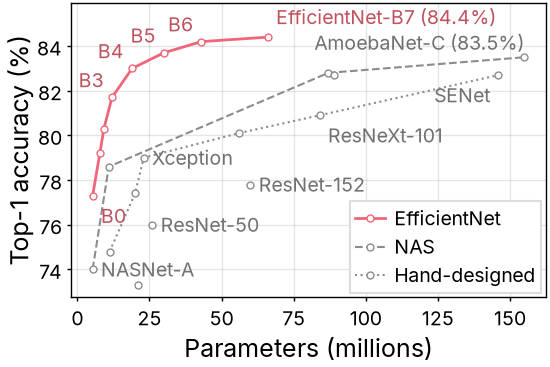

In [2]:
models = json.load(open("../data/accuracy-vs-parameters.json"))

fig, ax = plt.subplots(figsize=(2.75, 2))

families = [
    ("EfficientNet", "o-", colors["ours"], "EfficientNet"),
    ("NAS (dashed blue front)", "o--", colors["neutral"], "NAS"),
    ("hand-designed (dotted gray front)", "o:", colors["neutral"], "Hand-designed"),
    ("other (no line)", "o", colors["neutral"], None),
]
handles = []
for family, style, color, name in families:
    points = sorted((m for m in models if m["family"] == family), key=lambda m: m["params_millions"])
    x = [m["params_millions"] for m in points]
    y = [m["top1_accuracy"] for m in points]
    width = paper.dashed_width if style in ("o--", "o:") else None
    (line,) = ax.plot(x, y, style, color=color, linewidth=width, zorder=3 if family == "EfficientNet" else 2)
    if name:
        handles.append((line, name))

label_text = {
    "EfficientNet-B7": "EfficientNet-B7 (84.4%)",
    "AmoebaNet-C": "AmoebaNet-C (83.5%)",
}
offsets = {
    "EfficientNet-B0": (3, -3, "left", "top"),
    "EfficientNet-B3": (-3, 2, "right", "bottom"),
    "EfficientNet-B4": (-3, 2, "right", "bottom"),
    "EfficientNet-B5": (-3, 2, "right", "bottom"),
    "EfficientNet-B6": (-3, 2, "right", "bottom"),
    "EfficientNet-B7": (3, 3, "left", "bottom"),
    "AmoebaNet-C": (0, 1, "right", "bottom"),
    "SENet": (-3, -3, "right", "top"),
    "ResNeXt-101": (3, -3, "left", "top"),
    "ResNet-152": (3, 0, "left", "center"),
    "Xception": (3, 0, "left", "center"),
    "ResNet-50": (3, 0, "left", "center"),
    "NASNet-A (mobile)": (3, 0, "left", "center"),
}
for m in models:
    if m["model"] not in offsets:
        continue
    dx, dy, ha, va = offsets[m["model"]]
    color = colors["ours"] if m["family"] == "EfficientNet" else colors["neutral"]
    ax.annotate(label_text.get(m["model"], m["label_in_figure"]), (m["params_millions"], m["top1_accuracy"]),
                xytext=(dx, dy), textcoords="offset points", ha=ha, va=va, fontsize=7, color=darken(color))

ax.set_xlabel("Parameters (millions)")
ax.set_ylabel("Top-1 accuracy (%)")
ax.legend(*zip(*handles), loc="lower right")

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/accuracy-vs-parameters.pdf")
fig.savefig("../outputs/accuracy-vs-parameters.png")
plt.show()